02 – ECG Data Preprocessing
Chuẩn bị MIT-BIH cho mô hình 1D-CNN. Chỉ chia mitbih_train.csv thành Train/Validation; giữ nguyên mitbih_test.csv làm test cuối. Không gộp PTBDB vào bài toán 5 lớp. Các mẫu trùng và đoạn 0 chỉ thống kê, không tự động xóa.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Notebook đặt trong notebooks/; dữ liệu đặt trong data/ECG/raw/
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / 'data' / 'ECG' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'ECG' / 'processed'
SPLITS_DIR = PROJECT_ROOT / 'data' / 'ECG' / 'splits'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_FILE = RAW_DIR / 'mitbih_train.csv'
TEST_FILE = RAW_DIR / 'mitbih_test.csv'
print('Project root:', PROJECT_ROOT)
print('Train exists:', TRAIN_FILE.exists(), '| Test exists:', TEST_FILE.exists())
if not TRAIN_FILE.exists() or not TEST_FILE.exists():
    raise FileNotFoundError('Không thấy mitbih_train.csv / mitbih_test.csv. Kiểm tra vị trí notebook và data/ECG/raw/.')

Project root: d:\projects\nasa-challenge
Train exists: True | Test exists: True


In [2]:
train_df = pd.read_csv(TRAIN_FILE, header=None)
test_df = pd.read_csv(TEST_FILE, header=None)
assert train_df.shape[1] == 188 and test_df.shape[1] == 188, 'Mỗi file cần 187 điểm ECG + 1 cột nhãn.'
print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Missing train:', int(train_df.isna().sum().sum()))
print('Missing test:', int(test_df.isna().sum().sum()))
display(train_df.head())

Train: (87554, 188) | Test: (21892, 188)
Missing train: 0
Missing test: 0


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
X_train_all = train_df.iloc[:, :-1].to_numpy(dtype=np.float32)
y_train_all = train_df.iloc[:, -1].to_numpy(dtype=np.int64)
X_test = test_df.iloc[:, :-1].to_numpy(dtype=np.float32)
y_test = test_df.iloc[:, -1].to_numpy(dtype=np.int64)

classes = np.unique(y_train_all)
print('Classes:', classes)
print('Train finite:', np.isfinite(X_train_all).all())
print('Test finite:', np.isfinite(X_test).all())
print('Train min/max:', float(X_train_all.min()), float(X_train_all.max()))
print('Test min/max:', float(X_test.min()), float(X_test.max()))
assert np.isfinite(X_train_all).all() and np.isfinite(X_test).all(), 'Có NaN/Inf.'
assert np.array_equal(classes, np.array([0,1,2,3,4])), 'Nhãn không phải 0..4.'
if X_train_all.min() >= -1e-6 and X_train_all.max() <= 1.000001:
    print('Dữ liệu đã nằm trong [0,1]: giữ nguyên, không scale lần nữa.')
else:
    print('Giá trị ngoài [0,1]: chưa tự scale; cần kiểm tra nguồn/đơn vị.')

Classes: [0 1 2 3 4]
Train finite: True
Test finite: True
Train min/max: 0.0 1.0
Test min/max: 0.0 1.0
Dữ liệu đã nằm trong [0,1]: giữ nguyên, không scale lần nữa.


,class_id,class_name,count,percentage
0,0,N - Normal,72471,82.772917
1,1,S - Supraventricular ectopic,2223,2.539005
2,2,V - Ventricular ectopic,5788,6.610777
3,3,F - Fusion,641,0.732120
4,4,Q - Unknown/Other,6431,7.345181


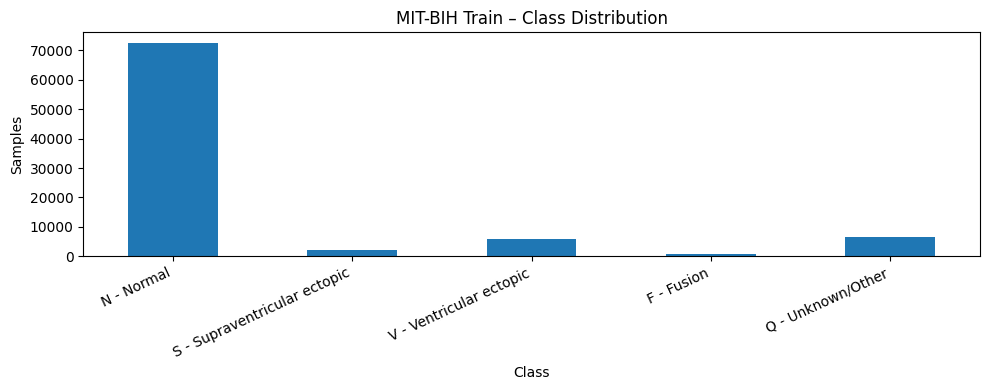

In [4]:
class_names = {
    0: 'N - Normal', 1: 'S - Supraventricular ectopic',
    2: 'V - Ventricular ectopic', 3: 'F - Fusion', 4: 'Q - Unknown/Other'
}
counts = pd.Series(y_train_all).value_counts().sort_index()
distribution = pd.DataFrame({'class_id': counts.index,
    'class_name': [class_names[int(i)] for i in counts.index],
    'count': counts.values, 'percentage': counts.values / len(y_train_all) * 100})
display(distribution)
ax = distribution.plot(x='class_name', y='count', kind='bar', legend=False, figsize=(10,4), title='MIT-BIH Train – Class Distribution')
ax.set_xlabel('Class'); ax.set_ylabel('Samples'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

In [5]:
# Chỉ thống kê mẫu trùng và zero; không tự động xóa.
train_duplicates = int(train_df.duplicated().sum())
test_duplicates = int(test_df.duplicated().sum())
train_all_zero = int(np.all(np.isclose(X_train_all, 0), axis=1).sum())
test_all_zero = int(np.all(np.isclose(X_test, 0), axis=1).sum())
def trailing_zero_count(row, atol=1e-8):
    nz = np.where(~np.isclose(row, 0.0, atol=atol))[0]
    return 0 if len(nz) == 0 else int(len(row)-1-nz[-1])
train_tz = np.array([trailing_zero_count(r) for r in X_train_all])
test_tz = np.array([trailing_zero_count(r) for r in X_test])
print('Duplicate rows train/test:', train_duplicates, '/', test_duplicates)
print('All-zero signals train/test:', train_all_zero, '/', test_all_zero)
print('Trailing-zero points median/max train:', float(np.median(train_tz)), '/', int(train_tz.max()))
print('Trailing-zero points median/max test:', float(np.median(test_tz)), '/', int(test_tz.max()))
print('Không cắt hoặc xóa các đoạn 0 tự động; cần xác minh chúng có phải padding hay không.')

Duplicate rows train/test: 0 / 0
All-zero signals train/test: 0 / 0
Trailing-zero points median/max train: 78.0 / 170
Trailing-zero points median/max test: 79.0 / 177
Không cắt hoặc xóa các đoạn 0 tự động; cần xác minh chúng có phải padding hay không.


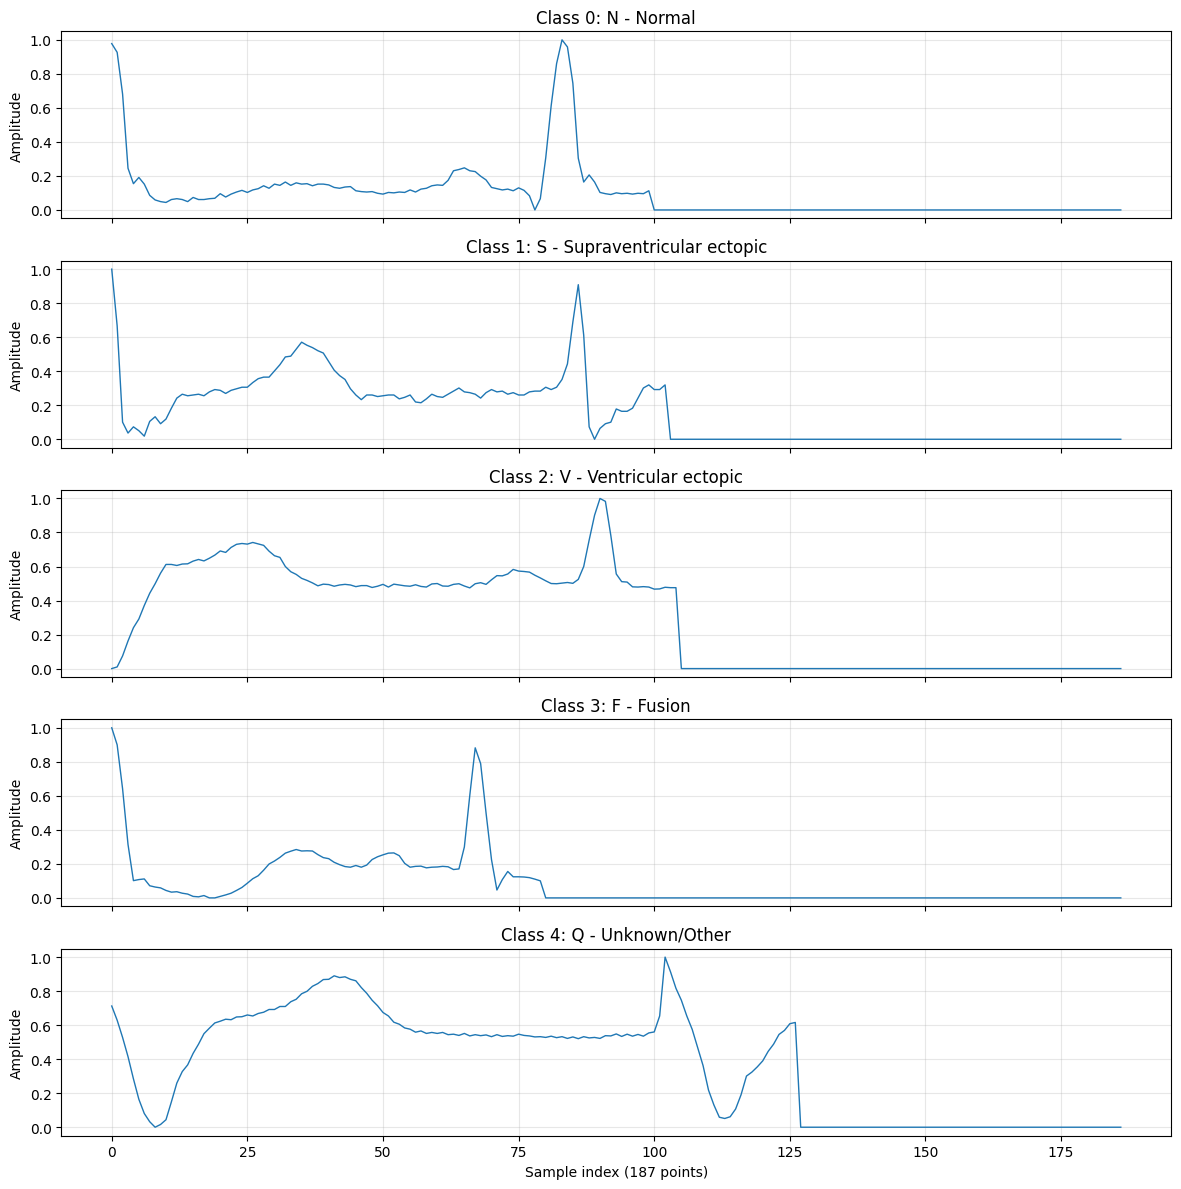

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(12,12), sharex=True)
for c, ax in enumerate(axes):
    idx = np.where(y_train_all == c)[0][0]
    ax.plot(X_train_all[idx], linewidth=1)
    ax.set_title(f'Class {c}: {class_names[c]}'); ax.set_ylabel('Amplitude'); ax.grid(alpha=0.3)
axes[-1].set_xlabel('Sample index (187 points)')
plt.tight_layout(); plt.show()

In [7]:
# Chia 80/20 từ MIT-BIH train, stratify để giữ tỷ lệ lớp.
indices = np.arange(len(y_train_all))
train_idx, val_idx = train_test_split(indices, test_size=0.20, random_state=RANDOM_SEED, stratify=y_train_all)
X_train, y_train = X_train_all[train_idx], y_train_all[train_idx]
X_val, y_val = X_train_all[val_idx], y_train_all[val_idx]
print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Official test:', X_test.shape, y_test.shape)

split_rows = []
for split_name, labels in [('train',y_train),('validation',y_val),('test',y_test)]:
    for c in range(5):
        n = int((labels == c).sum())
        split_rows.append({'split':split_name,'class_id':c,'class_name':class_names[c], 'count':n,'percentage':n/len(labels)*100})
split_df = pd.DataFrame(split_rows)
display(split_df)

Train: (70043, 187) (70043,)
Validation: (17511, 187) (17511,)
Official test: (21892, 187) (21892,)


,split,class_id,class_name,count,percentage
0,train,0,N - Normal,57977,82.773439
1,train,1,S - Supraventricular ectopic,1778,2.538441
2,train,2,V - Ventricular ectopic,4630,6.610225
3,train,3,F - Fusion,513,0.732407
4,train,4,Q - Unknown/Other,5145,7.345488
5,validation,0,N - Normal,14494,82.770830
6,validation,1,S - Supraventricular ectopic,445,2.541260
7,validation,2,V - Ventricular ectopic,1158,6.612986
8,validation,3,F - Fusion,128,0.730969
9,validation,4,Q - Unknown/Other,1286,7.343955


In [8]:
# Class weights chỉ tính từ TRAIN.
class_weights = compute_class_weight(class_weight='balanced', classes=np.array([0,1,2,3,4]), y=y_train).astype(np.float32)
display(pd.DataFrame({'class_id':range(5),'class_name':[class_names[i] for i in range(5)],'class_weight':class_weights}))
np.save(PROCESSED_DIR / 'class_weights.npy', class_weights)

,class_id,class_name,class_weight
0,0,N - Normal,0.241623
1,1,S - Supraventricular ectopic,7.878853
2,2,V - Ventricular ectopic,3.025615
3,3,F - Fusion,27.307213
4,4,Q - Unknown/Other,2.722760


In [9]:
# Lưu mảng float32. 1D-CNN sẽ reshape thành (N, 1, 187).
np.savez_compressed(PROCESSED_DIR / 'mitbih_processed.npz',
    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test, class_weights=class_weights)
pd.DataFrame({'original_train_row':train_idx}).to_csv(SPLITS_DIR / 'train_indices.csv', index=False)
pd.DataFrame({'original_train_row':val_idx}).to_csv(SPLITS_DIR / 'validation_indices.csv', index=False)
pd.DataFrame({'original_test_row':np.arange(len(y_test))}).to_csv(SPLITS_DIR / 'test_indices.csv', index=False)
split_df.to_csv(SPLITS_DIR / 'class_distribution_by_split.csv', index=False)
metadata = {'dataset':'Kaggle ECG Heartbeat Categorization - MIT-BIH', 'random_seed':RANDOM_SEED,
    'signal_length':187, 'num_classes':5, 'class_names':class_names,
    'train_samples':int(len(y_train)), 'validation_samples':int(len(y_val)), 'test_samples':int(len(y_test)),
    'normalization':'Original values retained after range check; no additional scaling applied.'}
with open(PROCESSED_DIR / 'metadata.json','w',encoding='utf-8') as f:
    json.dump(metadata,f,ensure_ascii=False,indent=2)
print('Đã lưu dữ liệu xử lý tại:', PROCESSED_DIR)
print('Đã lưu split tại:', SPLITS_DIR)

Đã lưu dữ liệu xử lý tại: d:\projects\nasa-challenge\data\ECG\processed
Đã lưu split tại: d:\projects\nasa-challenge\data\ECG\splits


Hoàn tất
Nếu các cell chạy hết không lỗi, dữ liệu đã sẵn sàng cho notebook huấn luyện 1D-CNN. Tập test chính thức được giữ nguyên, không dùng để chọn hyperparameter. Không báo hiệu năng trên dữ liệu mô phỏng như hiệu năng y khoa.

In [ ]:
# Kiểm tra file đầu ra
from pathlib import Path

processed = Path("../data/ECG/processed")
splits = Path("../data/ECG/splits")

for folder in [processed, splits]:
    print(f"\n{folder}:")
    for file in folder.glob("*"):
        print(file.name, f"({file.stat().st_size / 1024:.1f} KB)")


..\data\ECG\processed:
.gitkeep (0.0 KB)
class_weights.npy (0.1 KB)
metadata.json (0.5 KB)
mitbih_processed.npz (32924.4 KB)

..\data\ECG\splits:
.gitkeep (0.0 KB)
class_distribution_by_split.csv (0.8 KB)
test_indices.csv (138.8 KB)
train_indices.csv (470.2 KB)
validation_indices.csv (117.5 KB)
